================ HEA1 ================
Method 1 (Poly Chi^2) : p_c = 0.3830, nu = 1.0100 (chi^2 = 1.22)
Method 2 (Alignment)  : p_c = 0.3541, nu = 1.0100 (R     = 2.0409)

================ HEA2 ================
Method 1 (Poly Chi^2) : p_c = 0.4389, nu = 1.0100 (chi^2 = 0.44)
Method 2 (Alignment)  : p_c = 0.4123, nu = 1.0100 (R     = 0.9900)

================ HVA ================
Method 1 (Poly Chi^2) : p_c = 0.2614, nu = 1.1271 (chi^2 = 0.31)
Method 2 (Alignment)  : p_c = 0.2598, nu = 1.1101 (R     = 0.8147)



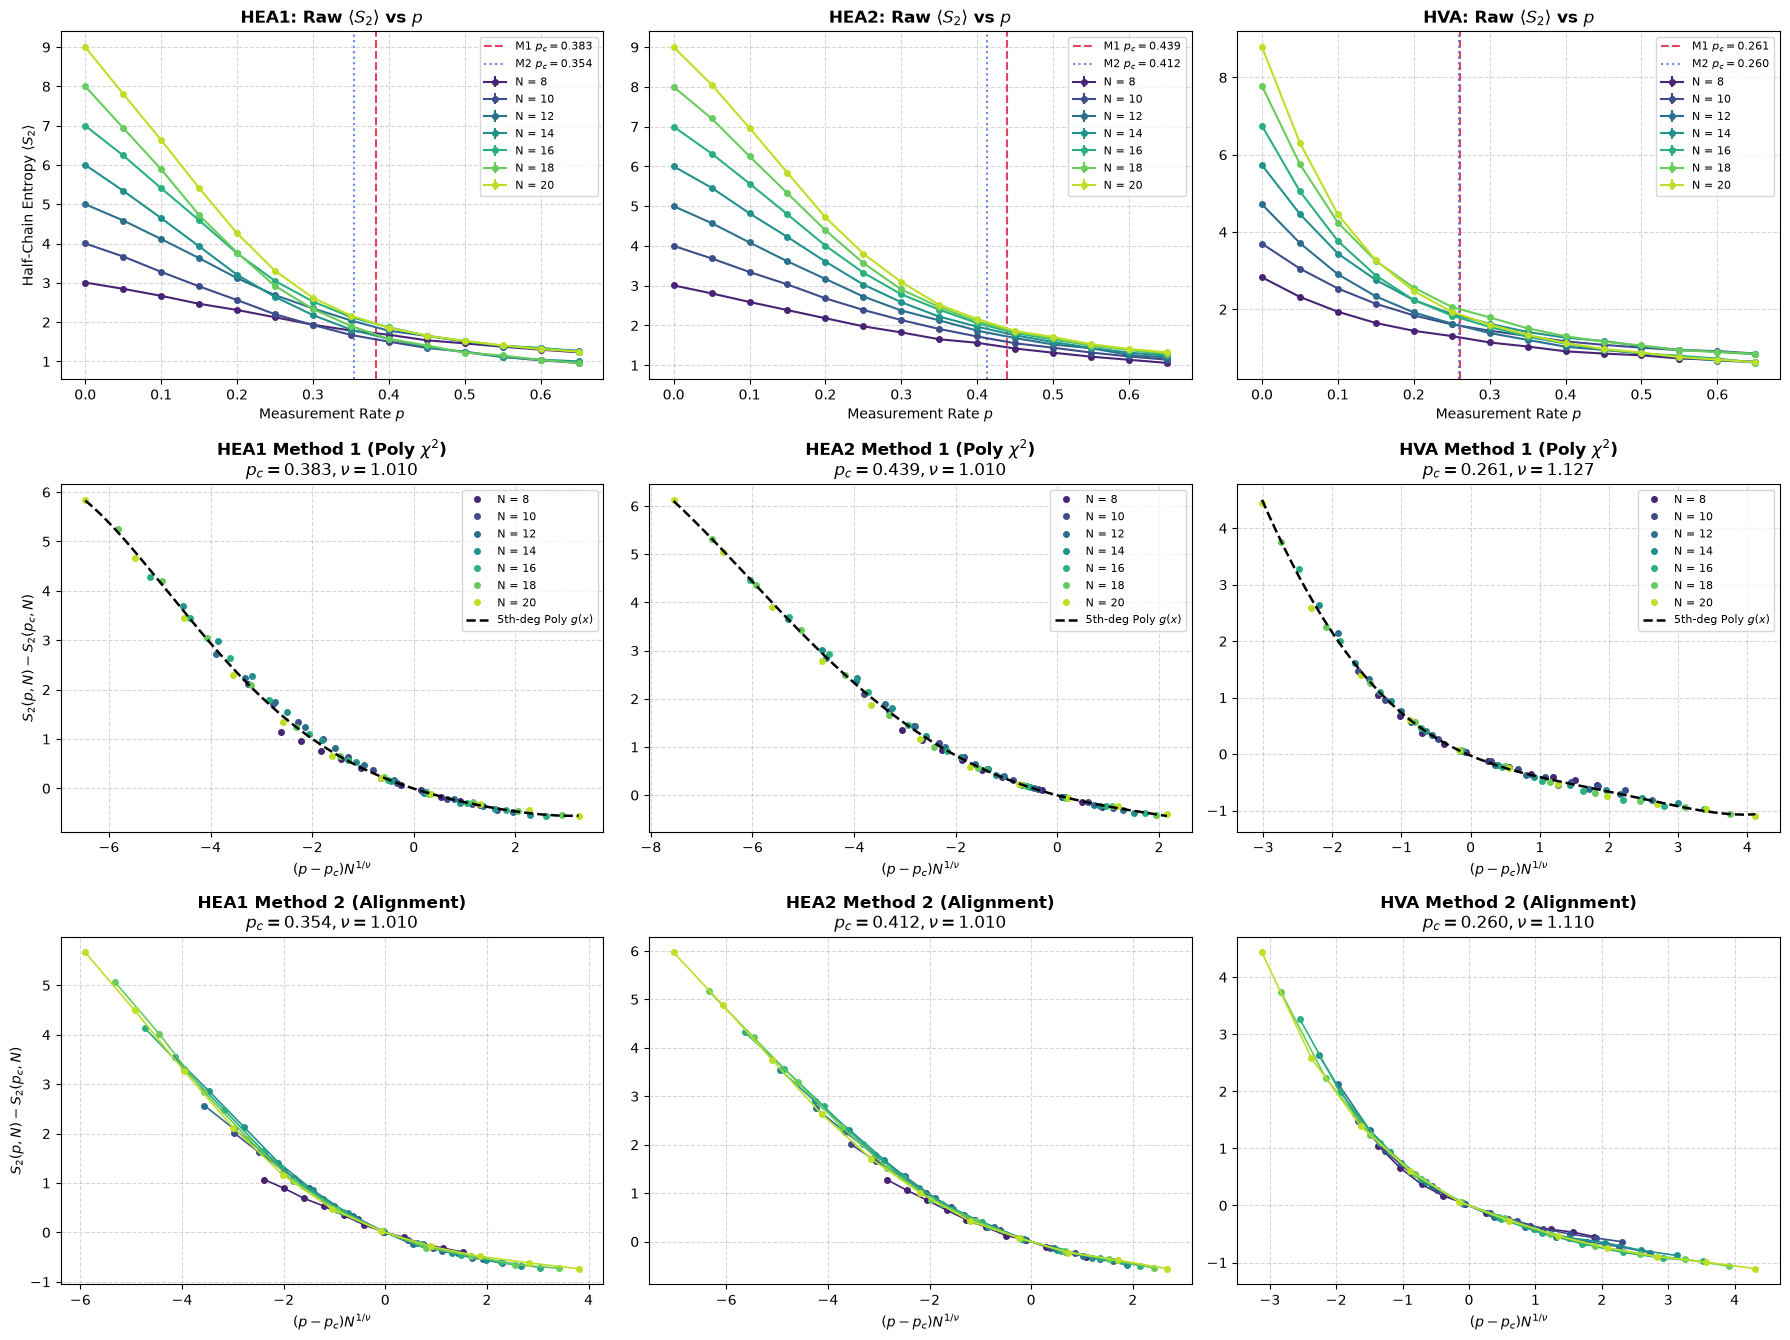

In [4]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =============================================================================
# METHOD 1: 5th-Degree Polynomial Fit & Chi-Squared Minimization (Corrected)
# =============================================================================
def fss_method_1_polynomial(p_array, N_array, S_data, std_S_data, p_bounds=(0.05, 0.55)):
    """
    Strictly implements Eq. (A.1) and Eq. (A.2) from Screenshot 1:
      S(N, p, nu) = S(N, p_c, nu) + g( N^(1/nu) * (p - p_c) )
      chi^2 = sum_i (S_data - S_tilde)^2 / Delta_S
    Uses Nelder-Mead over (p_c, nu) while solving the 5th-degree polynomial g(x)
    at each step to prevent 8D simplex divergence.
    """
    def evaluate_chi2_and_poly(pc, nu):
        x_all = []
        y_all = []
        w_all = []
        
        for N in N_array:
            # Estimate S(N, p_c) via linear interpolation
            S_pc = np.interp(pc, p_array, S_data[N])
            
            for i, p in enumerate(p_array):
                # Exclude p=0 where deterministic initial states can give Delta_S = 0
                if p < p_bounds[0] or p > p_bounds[1]:
                    continue
                
                delta_S = std_S_data[N][i]
                if delta_S <= 1e-12:
                    continue
                    
                x_i = (N ** (1.0 / nu)) * (p - pc)
                y_i = S_data[N][i] - S_pc
                
                x_all.append(x_i)
                y_all.append(y_i)
                # np.polyfit minimizes sum( (w_i * (y_i - poly(x_i)))^2 )
                # Setting w_i = 1 / sqrt(Delta_S) makes this exactly Eq. (A.2)!
                w_all.append(1.0 / np.sqrt(delta_S))
                
        x_all = np.asarray(x_all)
        y_all = np.asarray(y_all)
        w_all = np.asarray(w_all)
        
        # Fit 5th-degree polynomial g(x)
        poly_coeffs = np.polyfit(x_all, y_all, deg=5, w=w_all)
        y_fit = np.polyval(poly_coeffs, x_all)
        
        # Eq. (A.2): sum_i ( (S - S_tilde)^2 / Delta_S )
        chi2 = np.sum((w_all ** 2) * ((y_all - y_fit) ** 2))
        return chi2, poly_coeffs

    def objective(params):
        pc, nu = params[0], params[1]
        # Enforce strict bounds for Nelder-Mead
        if not (p_bounds[0] <= pc <= p_bounds[1]) or not (1.01 <= nu <= 8.0):
            return 1e15
        chi2, _ = evaluate_chi2_and_poly(pc, nu)
        return chi2

    # Multi-start grid over potential critical points p_c (as described in text)
    best_res = None
    for pc_init in np.linspace(0.10, 0.40, 7):
        res = minimize(
            objective, 
            x0=[pc_init, 1.35], 
            method='Nelder-Mead',
            options={'xatol': 1e-4, 'fatol': 1e-5, 'maxiter': 1000}
        )
        if best_res is None or res.fun < best_res.fun:
            best_res = res

    best_pc, best_nu = best_res.x
    _, best_poly = evaluate_chi2_and_poly(best_pc, best_nu)
    return best_pc, best_nu, best_res.fun, best_poly


# =============================================================================
# METHOD 2: Non-Parametric Curve Alignment R(p_c, nu) (Verified)
# =============================================================================
def fss_method_2_alignment(p_array, N_array, S_data, p_bounds=(0.05, 0.55)):
    """
    Strictly implements Eq. (A1) from Screenshot 2:
      R = sum_{i, L} [ y_L(x_i) - \bar{y}(x_i) ]^2
    where y_L(x) = S(p, L) - S(p_c, L) and x = (p - p_c) * L^(1/nu).
    """
    # Filter p_array to scaling region to prevent flat tail dominance
    mask = (p_array >= p_bounds[0]) & (p_array <= p_bounds[1])
    p_sub = p_array[mask]
    S_sub = {N: S_data[N][mask] for N in N_array}

    def objective(params):
        pc, nu = params[0], params[1]
        if not (p_bounds[0] <= pc <= p_bounds[1]) or not (1.01 <= nu <= 8.0):
            return 1e15
            
        S_pc = {N: np.interp(pc, p_sub, S_sub[N]) for N in N_array}
        x_data, y_data = {}, {}
        all_x = []
        
        for N in N_array:
            x_data[N] = (p_sub - pc) * (N ** (1.0 / nu))
            y_data[N] = S_sub[N] - S_pc[N]
            all_x.append(x_data[N])
            
        unique_x = np.unique(np.concatenate(all_x))
        R = 0.0
        n_overlap_pts = 0
        
        for x_i in unique_x:
            y_L_vals = []
            for N in N_array:
                # Only interpolate if x_i lies strictly inside the curve's domain
                if x_data[N][0] <= x_i <= x_data[N][-1]:
                    y_L_vals.append(np.interp(x_i, x_data[N], y_data[N]))
                    
            if len(y_L_vals) >= 2:
                y_bar = np.mean(y_L_vals)
                R += np.sum((np.asarray(y_L_vals) - y_bar) ** 2)
                n_overlap_pts += len(y_L_vals)
                
        # Protect against degenerate zero-overlap solutions
        if n_overlap_pts < len(N_array) * 3:
            return 1e15
        return R

    best_res = None
    for pc_init in np.linspace(0.10, 0.40, 7):
        res = minimize(
            objective, 
            x0=[pc_init, 1.35], 
            method='Nelder-Mead',
            options={'xatol': 1e-4, 'fatol': 1e-5, 'maxiter': 1000}
        )
        if best_res is None or res.fun < best_res.fun:
            best_res = res

    return best_res.x[0], best_res.x[1], best_res.fun


# =============================================================================
# MAIN PIPELINE: EXTRACT DATA & PLOT BOTH COLLAPSES
# =============================================================================
def analyze_and_plot_both_methods(filepath="data_mipt/mipt_s2_coarse_results.pkl", p_bounds=(0.05, 0.55)):
    with open(filepath, "rb") as f:
        payload = pickle.load(f)
        
    p_list = np.array(payload["p_list"], dtype=float)
    N_list = np.array(payload["N_list"], dtype=int)
    ansatz_list = payload["ansatz_list"]
    s2_mean = payload["s2_mean"]
    s2_sem = payload["s2_sem"]
    raw_s2 = payload.get("raw_s2", None)

    n_cols = len(ansatz_list)
    fig, axes = plt.subplots(3, n_cols, figsize=(6 * n_cols, 13.5), squeeze=False)
    cmap_N = plt.cm.viridis(np.linspace(0.1, 0.9, len(N_list)))

    for col_idx, ansatz in enumerate(ansatz_list):
        S_data = {N: np.array([s2_mean[ansatz][p][N] for p in p_list]) for N in N_list}
        sem_data = {N: np.array([s2_sem[ansatz][p][N] for p in p_list]) for N in N_list}
        
        # Extract true Standard Deviation (Delta S) for Method 1 Eq. (A.2)
        std_S_data = {}
        for N in N_list:
            if raw_s2 is not None:
                std_S_data[N] = np.array([np.std(raw_s2[ansatz][p][N], ddof=1) for p in p_list])
            else:
                # Reconstruct std from SEM if raw_s2 is missing: std = SEM * sqrt(samples)
                std_S_data[N] = sem_data[N] * np.sqrt(payload.get("samples", 2000))

        # 1. Run Method 1 (Polynomial Chi^2)
        pc1, nu1, chi2_val, poly_coeffs = fss_method_1_polynomial(
            p_list, N_list, S_data, std_S_data, p_bounds=p_bounds
        )
        
        # 2. Run Method 2 (Non-Parametric Alignment)
        pc2, nu2, R_val = fss_method_2_alignment(
            p_list, N_list, S_data, p_bounds=p_bounds
        )

        print(f"================ {ansatz} ================")
        print(f"Method 1 (Poly Chi^2) : p_c = {pc1:.4f}, nu = {nu1:.4f} (chi^2 = {chi2_val:.2f})")
        print(f"Method 2 (Alignment)  : p_c = {pc2:.4f}, nu = {nu2:.4f} (R     = {R_val:.4f})\n")

        # --- ROW 0: Raw Entropy Data ---
        ax0 = axes[0, col_idx]
        for n_idx, N in enumerate(N_list):
            ax0.errorbar(p_list, S_data[N], yerr=sem_data[N], fmt="o-", 
                         color=cmap_N[n_idx], lw=1.5, markersize=4, label=f"N = {N}")
        ax0.axvline(pc1, color="crimson", ls="--", alpha=0.8, label=f"M1 $p_c={pc1:.3f}$")
        ax0.axvline(pc2, color="royalblue", ls=":", alpha=0.8, label=f"M2 $p_c={pc2:.3f}$")
        ax0.set_title(f"{ansatz}: Raw $\\langle S_2 \\rangle$ vs $p$", fontweight="bold")
        ax0.set_xlabel("Measurement Rate $p$")
        if col_idx == 0: ax0.set_ylabel("Half-Chain Entropy $\\langle S_2 \\rangle$")
        ax0.grid(True, ls="--", alpha=0.5)
        ax0.legend(fontsize=8)

        # --- ROW 1: Method 1 Collapse (with 5th-degree polynomial curve) ---
        ax1 = axes[1, col_idx]
        x_min, x_max = np.inf, -np.inf
        mask = (p_list >= p_bounds[0]) & (p_list <= p_bounds[1])
        for n_idx, N in enumerate(N_list):
            x_sc = (p_list[mask] - pc1) * (N ** (1.0 / nu1))
            y_sc = S_data[N][mask] - np.interp(pc1, p_list, S_data[N])
            ax1.plot(x_sc, y_sc, "o", color=cmap_N[n_idx], markersize=4, label=f"N = {N}")
            x_min, x_max = min(x_min, x_sc.min()), max(x_max, x_sc.max())
            
        x_grid = np.linspace(x_min, x_max, 200)
        ax1.plot(x_grid, np.polyval(poly_coeffs, x_grid), "k--", lw=1.8, label="5th-deg Poly $g(x)$")
        ax1.set_title(f"{ansatz} Method 1 (Poly $\\chi^2$)\n$p_c={pc1:.3f}, \\nu={nu1:.3f}$", fontweight="bold")
        ax1.set_xlabel("$(p - p_c) N^{1/\\nu}$")
        if col_idx == 0: ax1.set_ylabel("$S_2(p, N) - S_2(p_c, N)$")
        ax1.grid(True, ls="--", alpha=0.5)
        ax1.legend(fontsize=8)

        # --- ROW 2: Method 2 Collapse (Curve Alignment) ---
        ax2 = axes[2, col_idx]
        for n_idx, N in enumerate(N_list):
            x_sc = (p_list[mask] - pc2) * (N ** (1.0 / nu2))
            y_sc = S_data[N][mask] - np.interp(pc2, p_list, S_data[N])
            ax2.plot(x_sc, y_sc, "o-", color=cmap_N[n_idx], lw=1.2, markersize=4, label=f"N = {N}")
        ax2.set_title(f"{ansatz} Method 2 (Alignment)\n$p_c={pc2:.3f}, \\nu={nu2:.3f}$", fontweight="bold")
        ax2.set_xlabel("$(p - p_c) N^{1/\\nu}$")
        if col_idx == 0: ax2.set_ylabel("$S_2(p, N) - S_2(p_c, N)$")
        ax2.grid(True, ls="--", alpha=0.5)

    plt.tight_layout()
    plt.savefig("mipt_s2_fss_both_methods_verified.png", dpi=300)
    plt.show()

if __name__ == "__main__":
    analyze_and_plot_both_methods("mipt_s2_coarse_results.pkl", p_bounds=(0.05, 0.55))